# 混合正态分布的抽样与直方图

> 对应代码：`MathStatsCode/code_in_notes/Chap.3/gaussian_mixture.do`（本 notebook 中的 Stata 代码与 do 文件一致）
>
> 运行方式：通过 *PyStata* 在 Jupyter 中调用 Stata，安装与使用说明见 `notebook/PyStata.md`。

**实验目的**：构造由两个正态分布混合而成的总体（约70%来自 N(-2,1)，约30%来自 N(2.5,0.8)），模拟1000个样本并用直方图观察混合分布的形态。


首先启动 Stata 环境，并把工作目录切换到 `code_in_notes/Chap.3`，这样 Stata 中的相对路径（如 `../datasets/...`）与同名 do 文件完全一致，图片也会输出到该目录。


In [1]:
# 配置 PyStata：启动 Stata 并注册 %%stata 魔法命令
import os
os.chdir("../../code_in_notes/Chap.3")

import stata_setup
stata_setup.config("/opt/Stata", "mp")


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      Stata 18.0
___/   /   /___/   /   /___/       MP—Parallel Edition

 Statistics and Data Science       Copyright 1985-2023 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-782-8272        https://www.stata.com
                                   979-696-4600        service@stata.com

Stata license: Single-user 16-core  perpetual
Serial number: 501806307019
  Licensed to: Keep calm and DO your research
               Jichun Si

Notes:
      1. Unicode is supported; see help unicode_advice.
      2. More than 2 billion observations are allowed; see help obs_advice.
      3. Maximum number of variables is set to 5,000 but can be increased;
          see help set_maxvar.


关闭分页显示（`set more off`）并清空内存中的数据（`clear`），为生成模拟数据做准备。


In [2]:
%%stata
set more off
clear
set obs 1000



. set more off

. clear

. set obs 1000
Number of observations (_N) was 0, now 1,000.

. 


**generate x1 and x0**

生成两个正态分布的随机样本：`x0=rnormal(2.5,sqrt(0.8))`，其中 `rnormal(m,s)` 的两个参数分别是**均值**和**标准差**，所以 x0 服从 N(2.5, 0.8)（方差为0.8）；`x1=rnormal(-2,1)` 服从 N(-2, 1)。它们将分别充当混合分布的两个“分量”。


In [3]:
%%stata
gen x0=rnormal(2.5,sqrt(0.8))
gen x1=rnormal(-2,1)



. gen x0=rnormal(2.5,sqrt(0.8))

. gen x1=rnormal(-2,1)

. 


**about 70% patient**

生成混合指示变量 d：`runiform()<0.7` 对每个观测返回 1 或 0 的逻辑值——约70%的观测取1、30%取0。这相当于一次成功概率为0.7的伯努利试验，d 用来决定每个观测来自哪个分量。


In [4]:
%%stata
gen d=runiform()<0.7


**generate x**

核心一步：`x = d*x1 + (1-d)*x0`。当 d=1 时 x 取 x1 分量，d=0 时取 x0 分量，从而得到混合分布（mixture distribution）的一个样本。这种“先抽分量、再抽分量内取值”的两步构造方法，是模拟混合分布的一般套路。


In [5]:
%%stata
gen x=d*x1+(1-d)*x0


**histogram**

`hist x` 绘制 x 的直方图。由于两个分量的均值分别为 2.5 和 -2，直方图应呈现明显的**双峰形态**——这正是混合分布区别于单一正态分布的特征。


(bin=29, start=-4.9085145, width=.33335702)


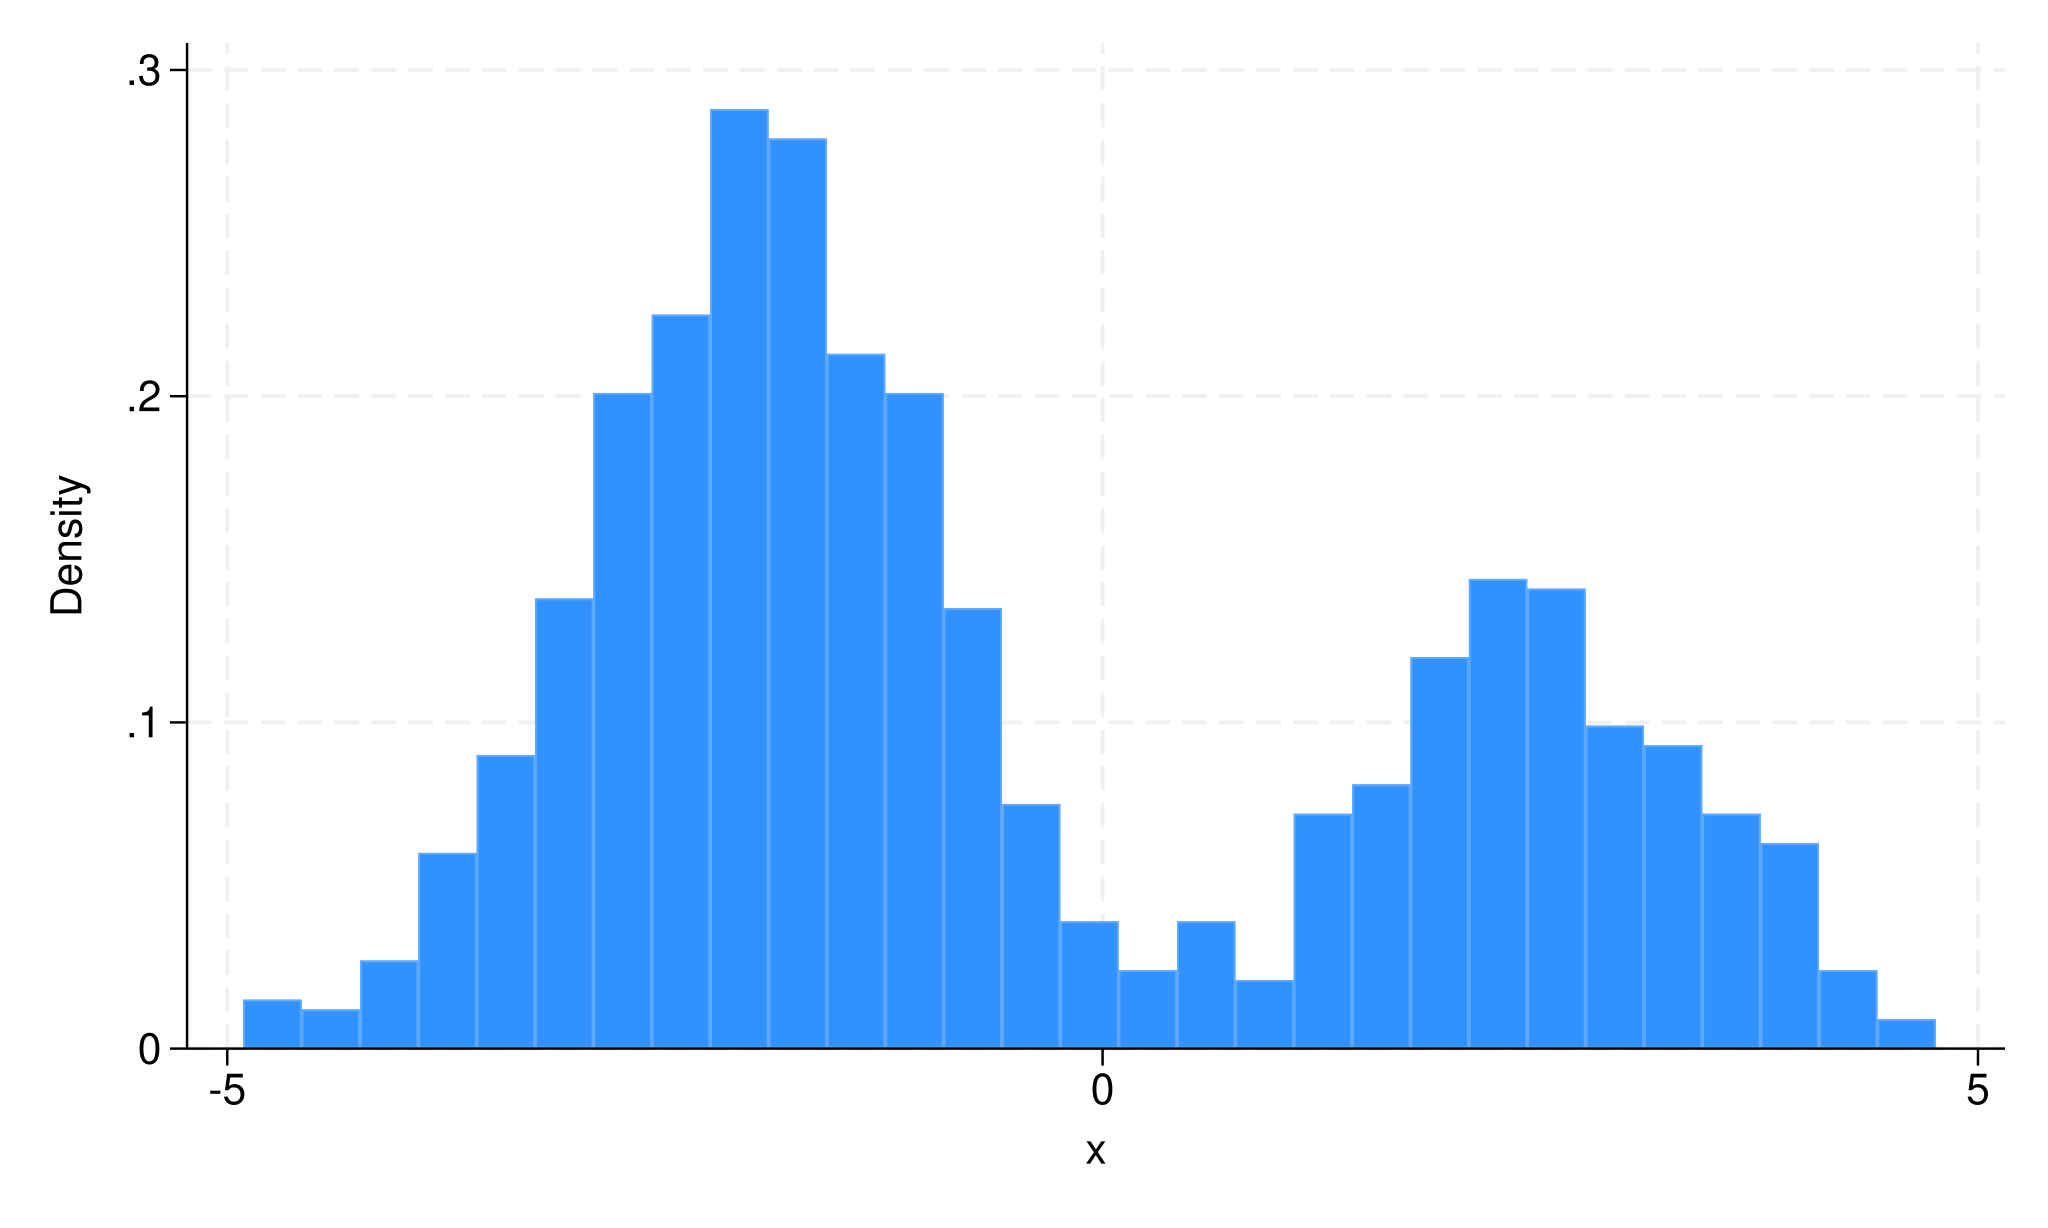

In [6]:
%%stata
hist x
